<a href="https://colab.research.google.com/github/erfano10/Modul-3-KKA_AVD_Kelompok-4/blob/main/Modul_3_KKA___AVD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Analisi dan Visualisasi Data (AVD)

### Kelompok 4 XI RPL 2
Nama Anggota Kelompok
1. Erfano Alfarrezal Raditya/11
2. Aryadasha Purwa Ramazan/04
3. Muhammad Gavrila Rafif Prayata/25
4. Ribkhi Fadhilatun Naura/32

### Latihan Praktikum

Skenario Praktikum: Kalian berperan sebagai Data Analyst magang di perusahaan retail daring
“Nusantara Mart”. Kalian diberikan dataset penjualan (berkas penjualan_nusantaramart.csv)
dan diminta menganalisis performa penjualan untuk mendukung pengambilan keputusan bisnis.

#### Latihan 1: Eksplorasi Data & Statistika Deskriptif dengan Pandas
*Tujuan: memuat dataset, melakukan eksplorasi awal, dan menghitung statistika deskriptif per
kategori*

In [ ]:
import pandas as pd
df = pd.read_csv('penjualan_nusantaramart.csv')
print(df.head()) # lihat 5 baris pertama
print(df.info()) # tipe data & jumlah data kosong
print(df.describe()) # ringkasan statistik
# rata-rata total pembelian per kategori produk
rata_kategori = df.groupby('kategori_produk')['total'].mean()
print(rata_kategori.sort_values(ascending=False))

   order_id     tanggal    kategori_produk        nama_produk   wilayah  \
0      1146  2026-01-03           Olahraga        Matras Yoga    Malang   
1      1166  2026-01-05            Fashion       Celana Jeans  Surabaya   
2      1190  2026-01-05          Kesehatan   Masker Medis Box  Semarang   
3      1219  2026-01-08  Makanan & Minuman  Kopi Kemasan 200g   Bandung   
4      1133  2026-01-10            Fashion         Tas Ransel  Surabaya   

   jumlah  harga_satuan   total metode_pembayaran  rating_pelanggan  
0       5         90000  450000          E-Wallet                 4  
1       5        175000  875000     Transfer Bank                 5  
2       4         30000  120000      Kartu Kredit                 3  
3       4         28000  112000          E-Wallet                 3  
4       4        130000  520000      Kartu Kredit                 4  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 10 columns):
 #   Column             

##### Tugas Analisis 1:
• Kategori produk apa yang memiliki rata-rata nilai transaksi (total) tertinggi?

*Kategori produk yang memiliki rata-rata nilai transaksi (total) tertinggi adalah Elektronik dengan rata-rata sebesar Rp 363.541,67.*


---


• Apakah ada kolom yang memiliki data kosong (missing value)?

*tidak ada kolom yang memiliki data kosong.*

Bagaimana cara mengeceknya dari
output df.info()?

1. *Perhatikan kolom Non-Null Count pada setiap kolom dari nomor 0 hingga 9.*

2. *Semua kolom menunjukkan angka 220 non-null, yang sama persis dengan total baris data (RangeIndex: 220 entries, 0 to 219).*

3. *Jika ada data yang kosong, angka non-null count akan lebih kecil dari total baris (misalnya 215 non-null dari 220 baris). Karena semuanya bernilai 220, maka dipastikan data lengkap dan bersih dari missing value.*


---


• Bandingkan nilai mean dan median kolom total secara keseluruhan. Apa yang bisa kamu
simpulkan tentang sebaran datanya?

*Nilai mean (Rp 238.486,40) jauh lebih besar daripada nilai median (Rp 125.000,00). Hal ini mengindikasikan bahwa sebaran data kolom total bersifat cenderung menceng ke kanan (right-skewed). Artinya, terdapat sebagian kecil transaksi dengan nilai total yang sangat tinggi (seperti terlihat pada nilai maksimum yang mencapai Rp 3.400.000 akibat pembelian jumlah banyak/produk mahal), yang menarik nilai rata-rata naik ke atas, sementara sebagian besar transaksi nilainya berada di bawah rata-rata tersebut.*



#### Latihan 2: Visualisasi Perbandingan dengan Bar Chart
*Tujuan: membandingkan total penjualan antar-kategori produk.*

/tmp/ipykernel_1709/3024874420.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')


Text(0, 0.5, 'Kategori Produk')

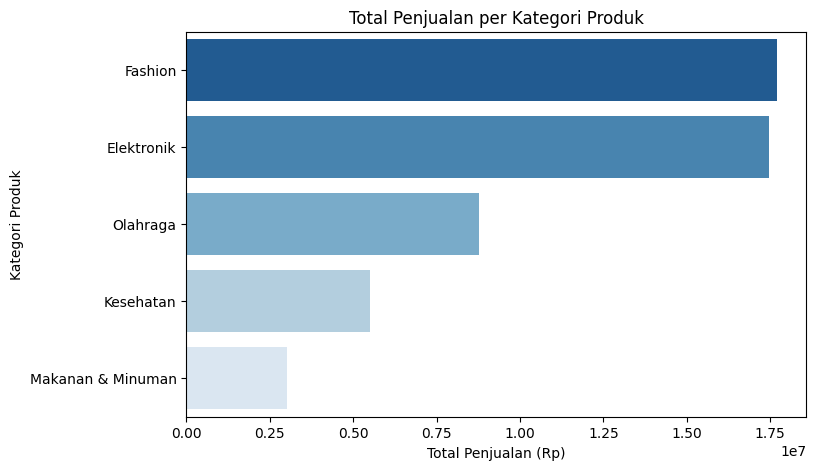

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)
plt.figure(figsize=(8,5))
sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Kategori Produk')

##### Tugas Analisis 2

• Kategori apa yang menyumbang penjualan tertinggi dan terendah?

*Kategori yang menyumbang penjualan tertinggi yaitu kategori Fashion dan kategori yang menyumbang penjualan terendah yaitu kategori Makanan dan minuman.*


---


• Menurutmu, apa rekomendasi bisnis yang bisa diberikan kepada manajer Nusantara Mart
berdasarkan grafik ini?

*Saya akan merekomendasikan bisnis dengan kategori fashion,karena menurut grafik kategori fashion menjadi penyumbang penjualan tertinggi.*

#### Latihan 3: Visualisasi Tren dengan Line Chart
*Tujuan: melihat pola tren penjualan dari waktu ke waktu.*

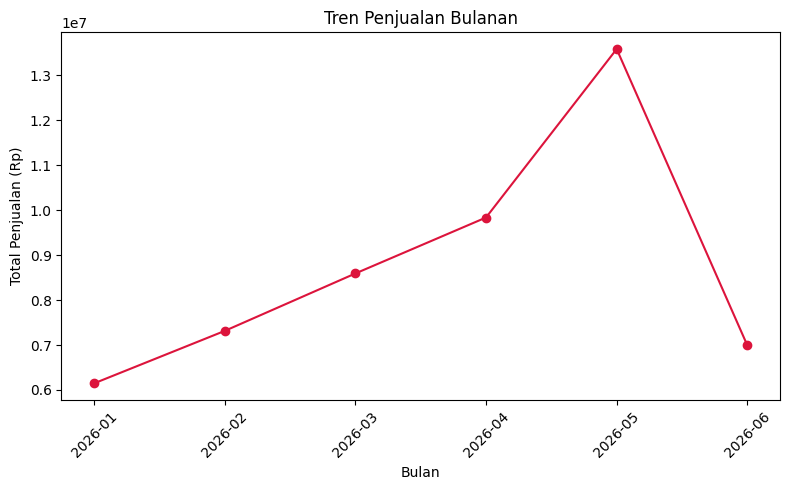

In [ ]:
df['tanggal'] = pd.to_datetime(df['tanggal'])
df['bulan'] = df['tanggal'].dt.to_period('M')
tren_bulanan = df.groupby('bulan')['total'].sum()
plt.figure(figsize=(8,5))
plt.plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o', color='crimson')
plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### Tugas Analisis 3:

• Bulan apa yang memiliki penjualan tertinggi? Menurutmu, apa kemungkinan penyebabnya?

*Bulan Mei 2026 (2026-05) dengan total penjualan mencapai angka tertinggi di atas Rp 1,3e7 dan kemungkinan penyebabnya adanya program promosi besar-besaran, diskon spesial (flash sale), atau peluncuran produk baru yang menarik minat beli konsumen secara masif pada bulan tersebut.*


---


• Apakah tren penjualan cenderung naik, turun, atau fluktuatif? Jelaskan.

*Tren penjualan secara keseluruhan dari bulan Januari hingga Mei menunjukkan pola yang cenderung naik (increasing), namun secara garis besar polanya dapat dikatakan fluktuatif karena mengalami penurunan tajam yang signifikan pada bulan Juni 2026 (2026-06).*



#### Latihan 4: Visualisasi Hubungan dengan Scatter Plot
*Tujuan: melihat hubungan antara jumlah barang yang dibeli dengan total nilai pembelian.*

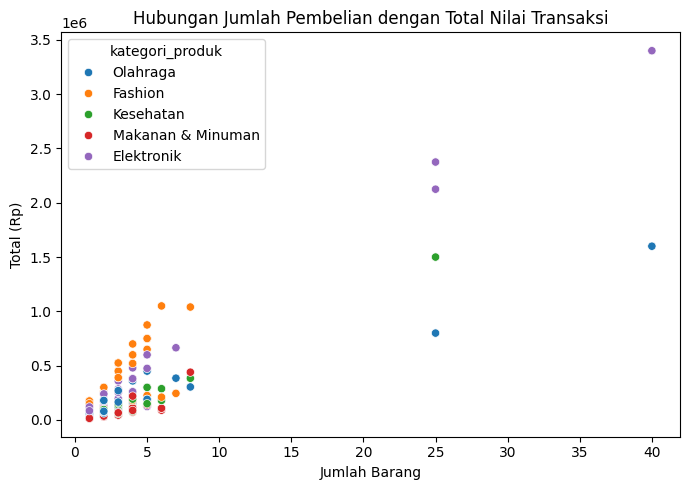

In [ ]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='jumlah', y='total', hue='kategori_produk')
plt.title('Hubungan Jumlah Pembelian dengan Total Nilai Transaksi')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total (Rp)')
plt.tight_layout()
plt.show()

##### Tugas Analisis 4

1. **Apakah terlihat pola hubungan antara jumlah barang dan total nilai transaksi?**
- Jelaskan
Berdasarkan grafik scatter plot, terlihat adanya hubungan positif antara jumlah barang yang dibeli dengan total nilai transaksi. Artinya, semakin banyak jumlah barang yang dibeli, umumnya semakin besar pula total nilai transaksinya. Namun, nilai transaksi juga dipengaruhi oleh kategori produk karena setiap kategori memiliki harga barang yang berbeda-beda.hubungan tersebut (positif/negatif/tidak berhubungan).


---


2. **Apakah ada titik data yang terlihat jauh dari pola umum (kemungkinan outlier)? Sebutkan
kategorinya jika terlihat dari warna.**

- Selain itu, terdapat beberapa titik data yang terlihat jauh dari pola umum (outlier). Outlier tersebut terlihat pada kategori Elektronik (ungu), Olahraga (biru), dan Kesehatan (hijau). Hal ini terlihat dari jumlah pembelian yang mencapai 25 hingga 40 barang, sedangkan sebagian besar data lainnya hanya berada pada kisaran 1–8 barang. Dengan demikian, dapat disimpulkan bahwa terdapat beberapa transaksi dengan jumlah pembelian dan nilai transaksi yang jauh lebih tinggi dibandingkan transaksi lainnya.*

#### Latihan 5: Visualisasi Distribusi & Deteksi Outlier (Histogram & Boxplot)

*Tujuan: melihat sebaran rating pelanggan dan mendeteksi transaksi tidak wajar (outlier) pada
kolom jumlah.*

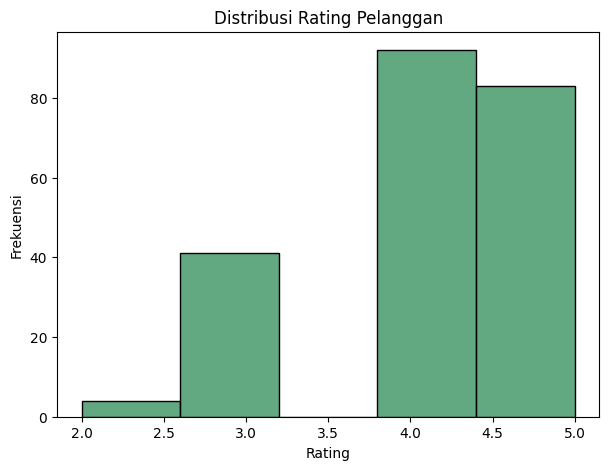

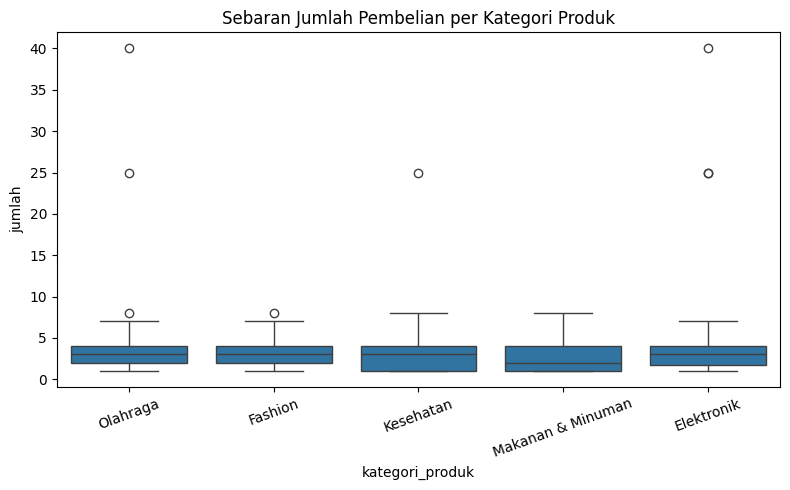

In [ ]:
# Histogram distribusi rating pelanggan
plt.figure(figsize=(7,5))
sns.histplot(df['rating_pelanggan'], bins=5, color='seagreen')
plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.show()
# Boxplot jumlah pembelian per kategori (deteksi outlier)
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='kategori_produk', y='jumlah')
plt.title('Sebaran Jumlah Pembelian per Kategori Produk')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

##### ANALISIS LATIHAN 5

1. **Distribusi Rating Pelanggan**

   - Distribusi rating pelanggan dapat dilihat dari histogram. Jika sebagian besar data berada pada rating tinggi (4–5), berarti pelanggan cenderung memberikan penilaian yang baik terhadap produk. Namun, jika penyebarannya merata, berarti penilaian pelanggan cukup bervariasi.

2. **Outlier pada Boxplot Jumlah Pembelian**

   - Kategori produk yang memiliki titik-titik di luar kotak boxplot menunjukkan adanya outlier atau jumlah pembelian yang tidak biasa. Hal ini bisa terjadi karena beberapa pelanggan membeli produk dalam jumlah besar, misalnya reseller yang membeli barang untuk dijual kembali, atau adanya pembelian khusus dalam jumlah banyak.

#### Latihan 6: Menggabungkan Grafik dalam Dashboard Sederhana

*Tujuan: menggabungkan beberapa visualisasi ke dalam satu tampilan (dashboard)
menggunakan subplot.*

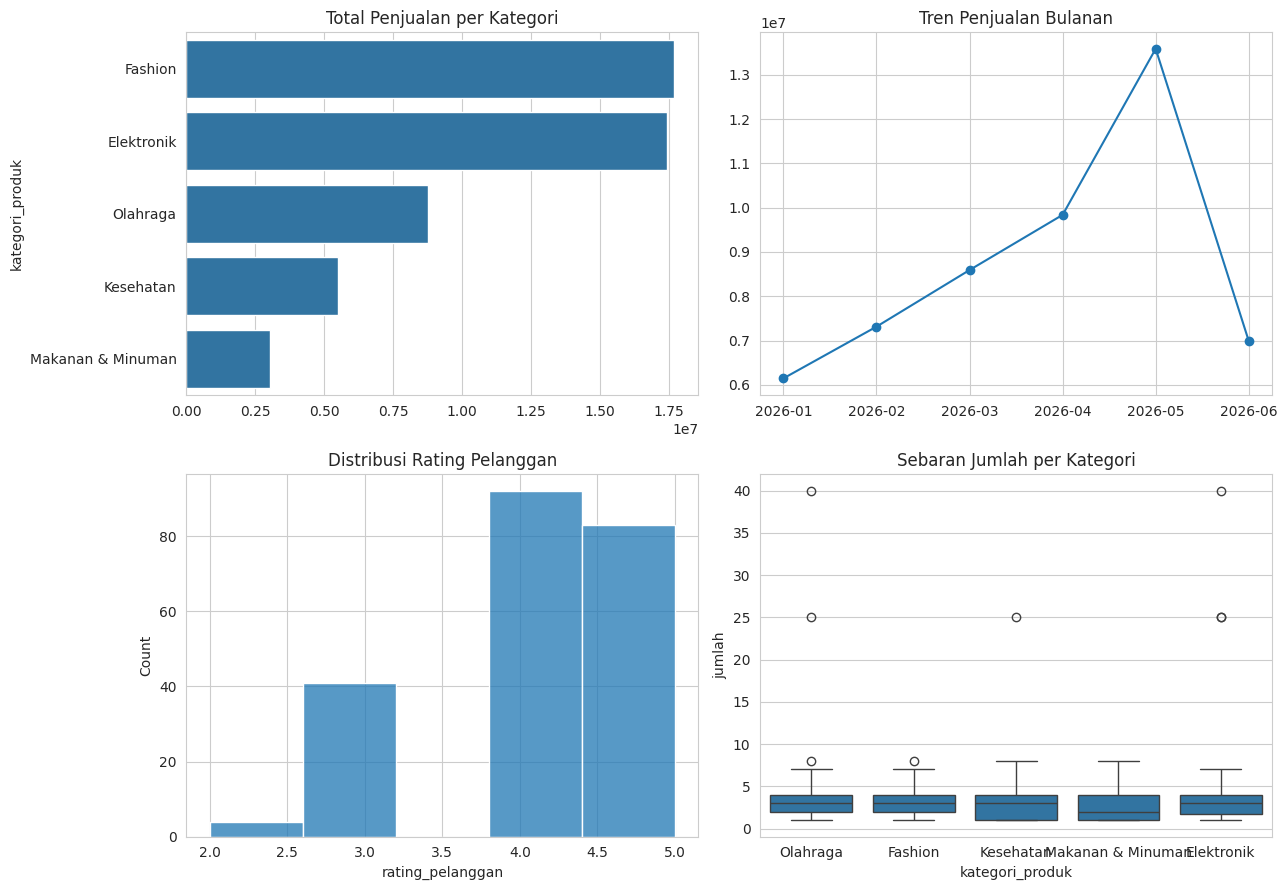

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13,9))
sns.barplot(x=total_kategori.values, y=total_kategori.index, ax=axes[0,0])
axes[0,0].set_title('Total Penjualan per Kategori')
axes[0,1].plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o')
axes[0,1].set_title('Tren Penjualan Bulanan')
sns.histplot(df['rating_pelanggan'], bins=5, ax=axes[1,0])
axes[1,0].set_title('Distribusi Rating Pelanggan')
sns.boxplot(data=df, x='kategori_produk', y='jumlah', ax=axes[1,1])
axes[1,1].set_title('Sebaran Jumlah per Kategori')
plt.tight_layout()
plt.show()

#### Tugas Analisis 6

1. **Keuntungan Menyajikan Visualisasi dalam Dashboard:**
   - Memungkinkan pengambil keputusan melihat gambaran holistik (ringkasan perbandingan, tren, distribusi, dan outlier) dalam satu tampilan terpadu tanpa harus berpindah-pindah grafik. Hal ini mempermudah identifikasi korelasi antar-variabel secara cepat.

2. **Keputusan Bisnis Berbasis Dashboard:**
   - Alokasi Stok:Memprioritaskan alokasi gudang pada kategori terlaris berdasarkan Bar Chart
   Perencanaan Promosi:Menyusun kalender diskon pada bulan-bulan dengan tren penjualan rendah berdasarkan Line Chart.
   Kebijakan Pembelian Grosir: Membuat saluran atau harga khusus untuk segmen *reseller* yang terdeteksi pada outlier Boxplot